In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose


In [2]:
dates = pd.date_range("2023-01-01", periods=180, freq="D")
np.random.seed(0)
page_views = (
    500
    + np.arange(180) * 2
    + 100 * np.sin(np.arange(180) * 2 * np.pi / 30)
    + np.random.normal(0, 30, 180)
)
unique_visitors = page_views * 0.6 + np.random.normal(0, 20, 180)
bounce_rate = (
    40 + 5 * np.sin(np.arange(180) * 2 * np.pi / 60) + np.random.normal(0, 2, 180)
)
data = pd.DataFrame(
    {
        "Date": dates,
        "Page_Views": page_views,
        "Unique_Visitors": unique_visitors,
        "Bounce_Rate": bounce_rate,
    }
)
data.set_index("Date", inplace=True)
data.iloc[10:12] = (
    data.iloc[10:12].interpolate().fillna(method="bfill").values
    if False
    else data.iloc[10:12]
)
print(data.head())


            Page_Views  Unique_Visitors  Bounce_Rate
Date                                                
2023-01-01  552.921570       324.673064    41.396914
2023-01-02  534.795885       293.378505    40.530184
2023-01-03  574.035804       331.549114    42.903255
2023-01-04  632.005321       334.735130    42.225015
2023-01-05  638.341222       395.509362    42.002319


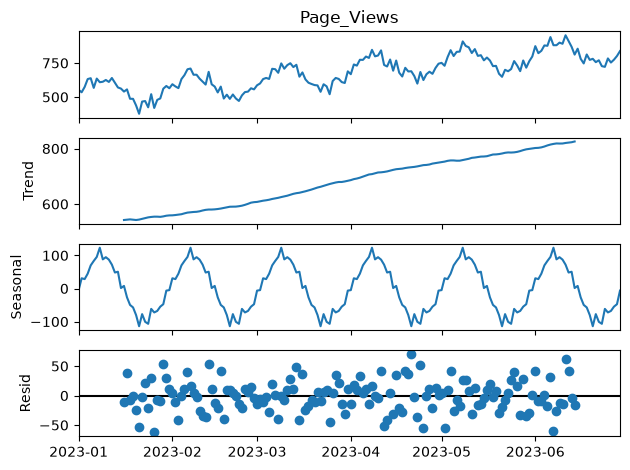

In [3]:
decomposition = seasonal_decompose(data["Page_Views"], model="additive", period=30)
decomposition.plot()
plt.show()


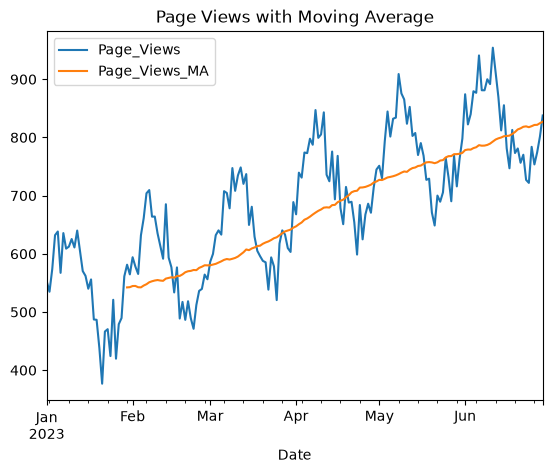

In [4]:
data["Page_Views_MA"] = data["Page_Views"].rolling(window=30).mean()
data[["Page_Views", "Page_Views_MA"]].plot()
plt.title("Page Views with Moving Average")
plt.show()


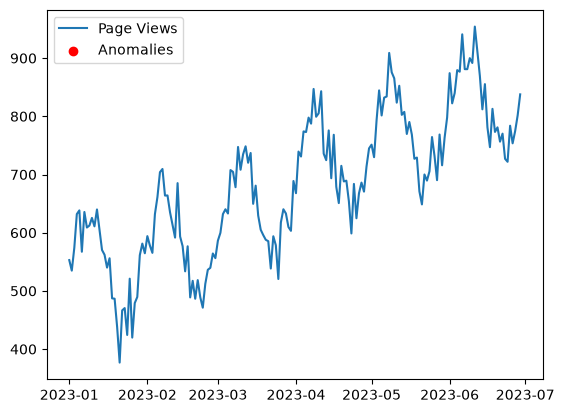

In [5]:
data["Page_Views_Z"] = (data["Page_Views"] - data["Page_Views"].mean()) / data[
    "Page_Views"
].std()
anomalies = data[data["Page_Views_Z"].abs() > 3]
plt.plot(data.index, data["Page_Views"], label="Page Views")
plt.scatter(anomalies.index, anomalies["Page_Views"], color="red", label="Anomalies")
plt.legend()
plt.show()
